# Assignment

## Q1.
- Assignment: Add a RescaleIntensity transform here and clip it to a range betweeen 0% and 99.5%
- https://torchio.readthedocs.io/transforms/preprocessing.html

## Q2.
- Assignment: Replace the Generator network with a UNet of your choice. (Extra Points if you replace it with a SwinUNETR)

## Q3.
- Assignment: Create a WANDB account and generate an API Key. Place the API Key in the 'WANDB Logging' Cell to Track your Experiment.
- https://wandb.ai/


# Example Results

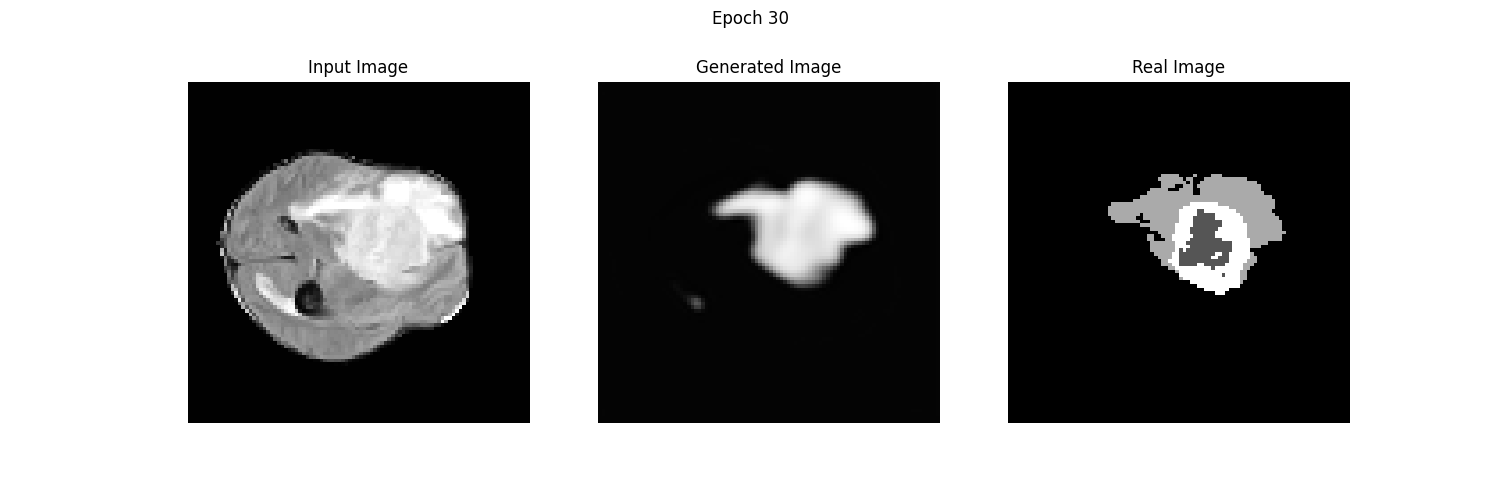

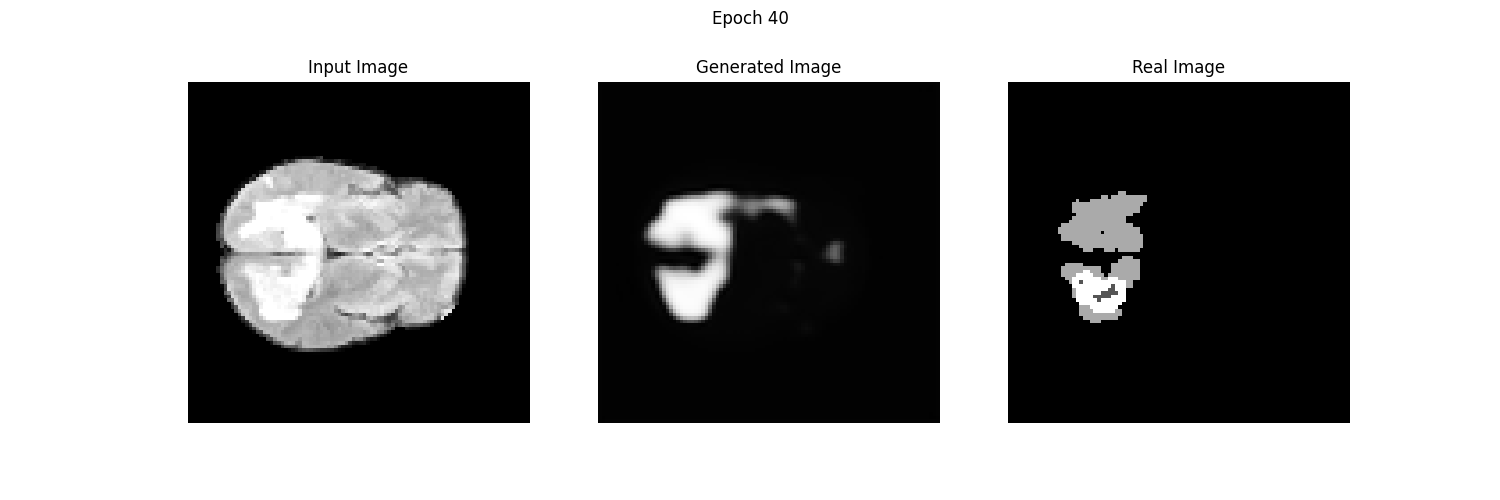

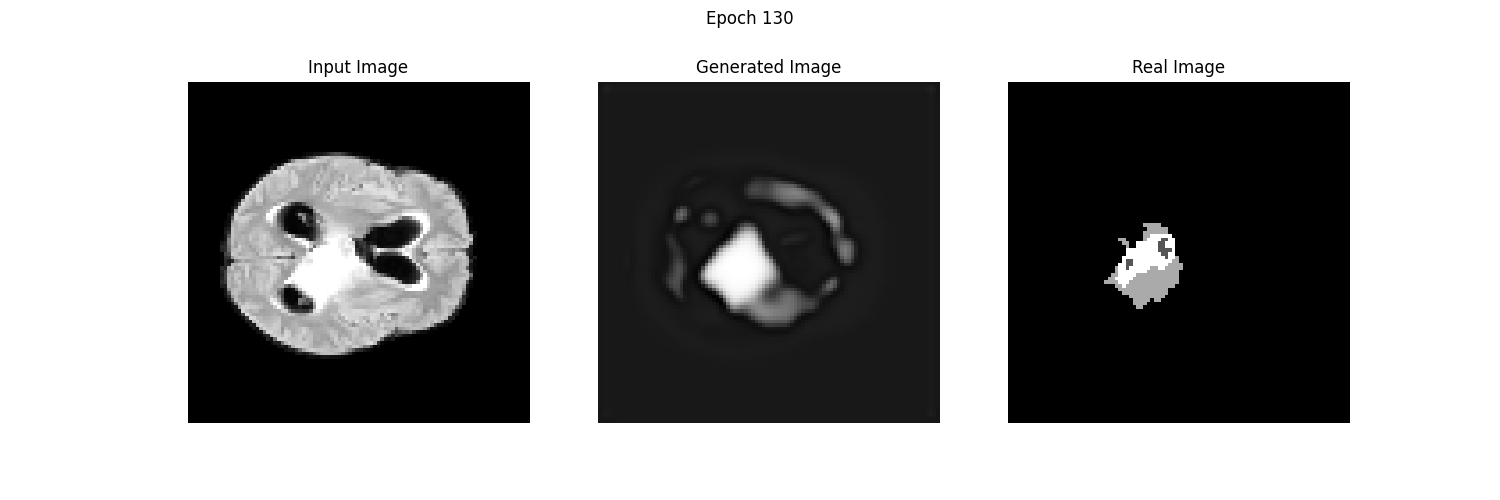

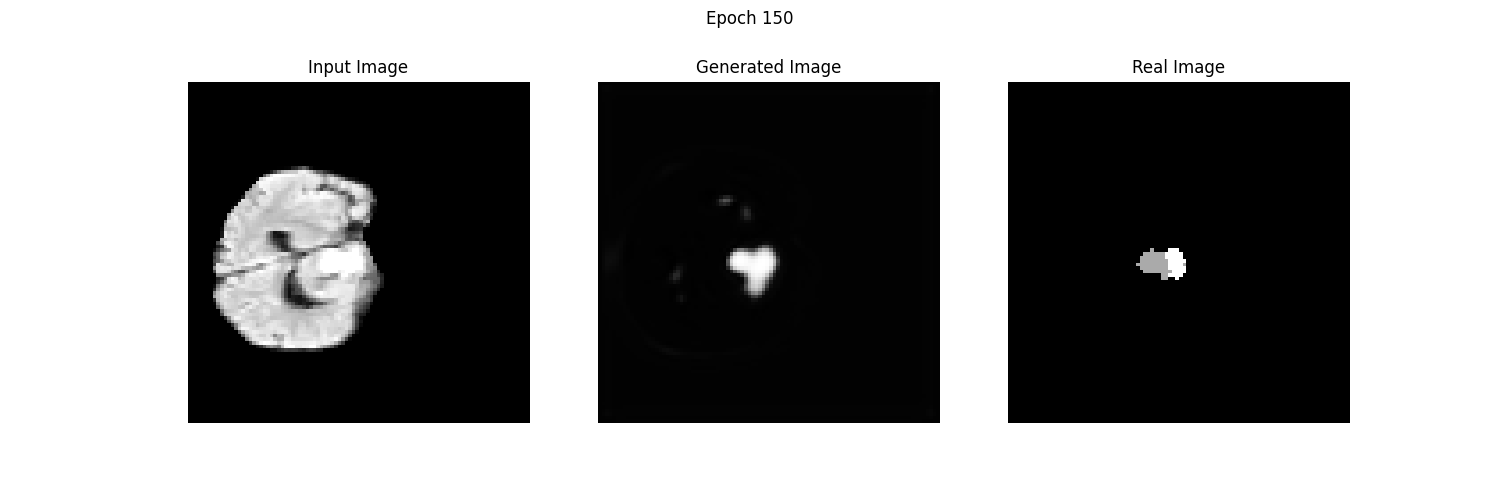

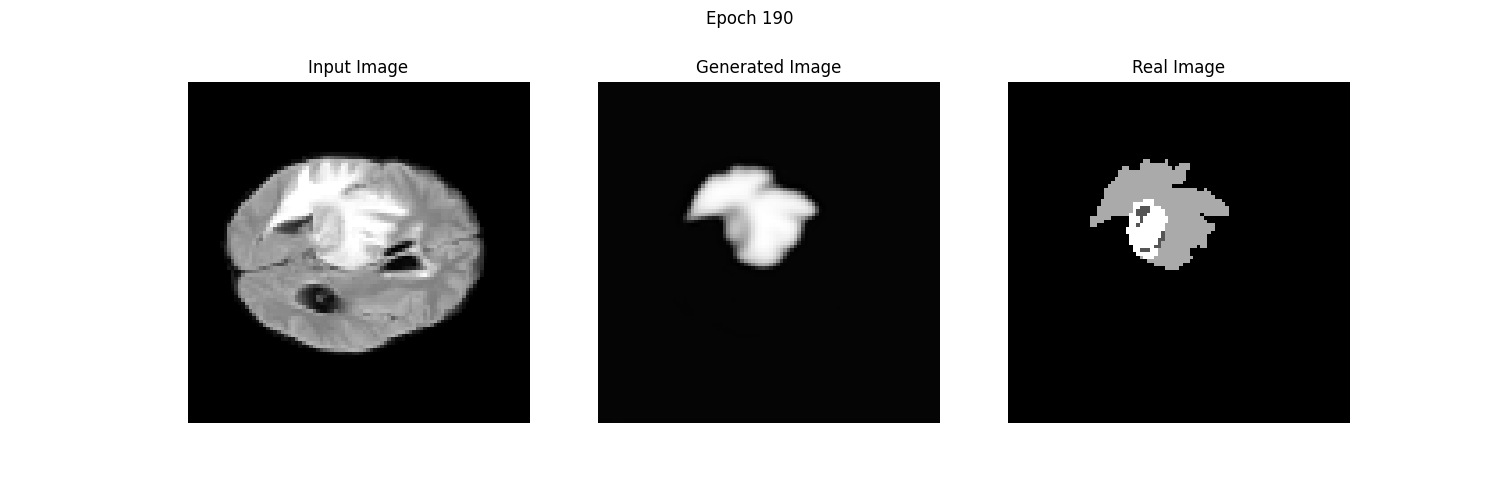
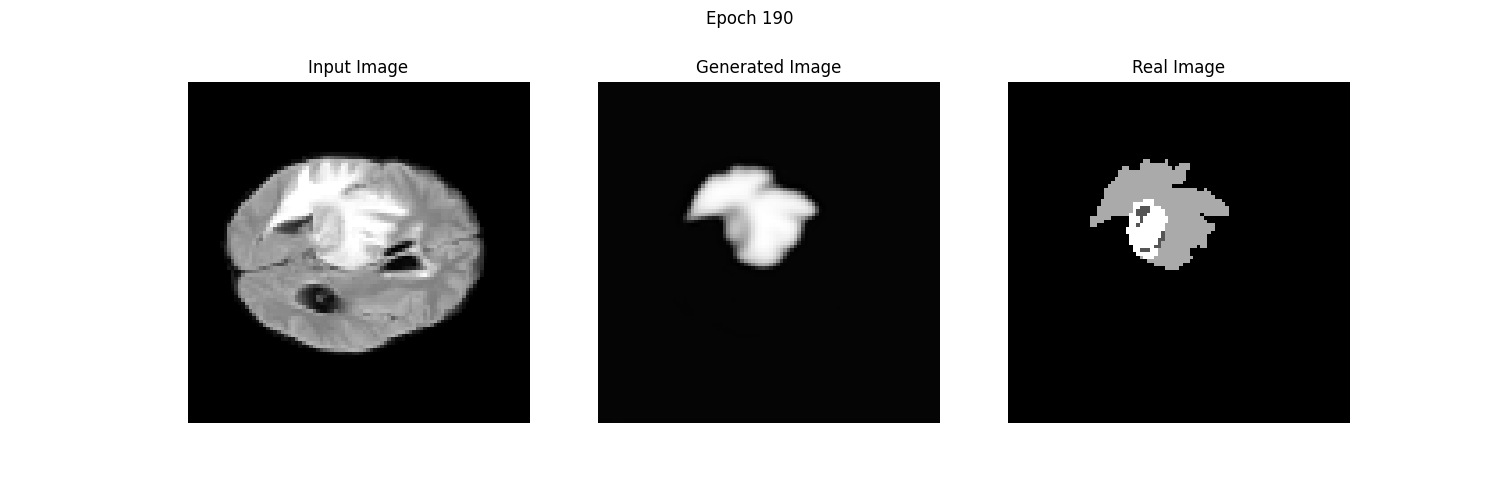
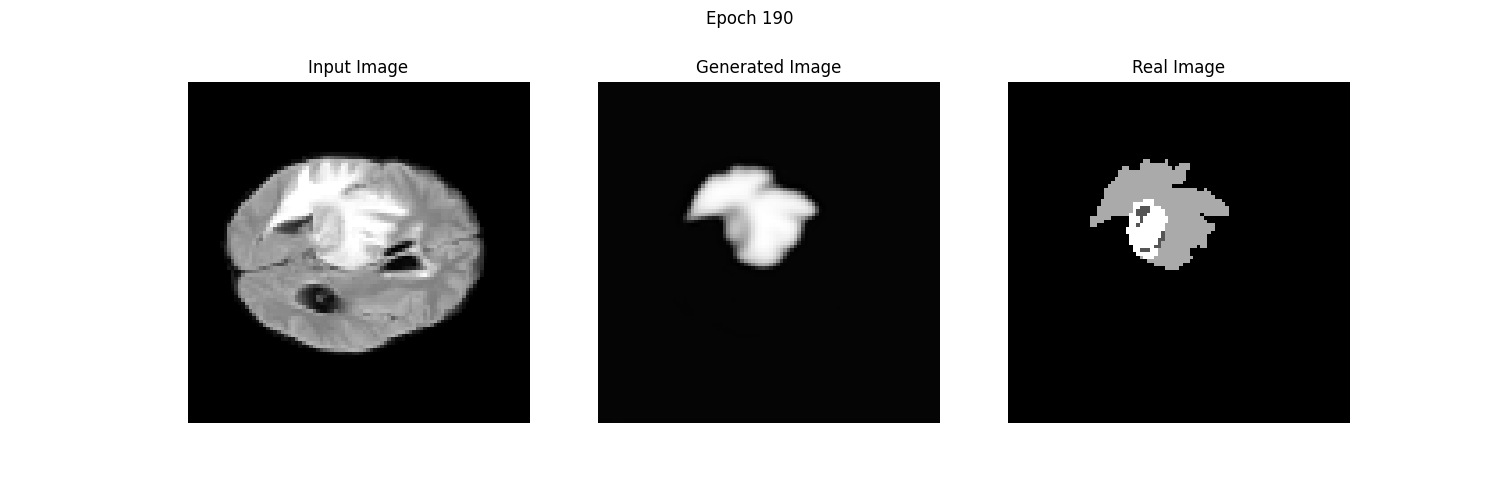
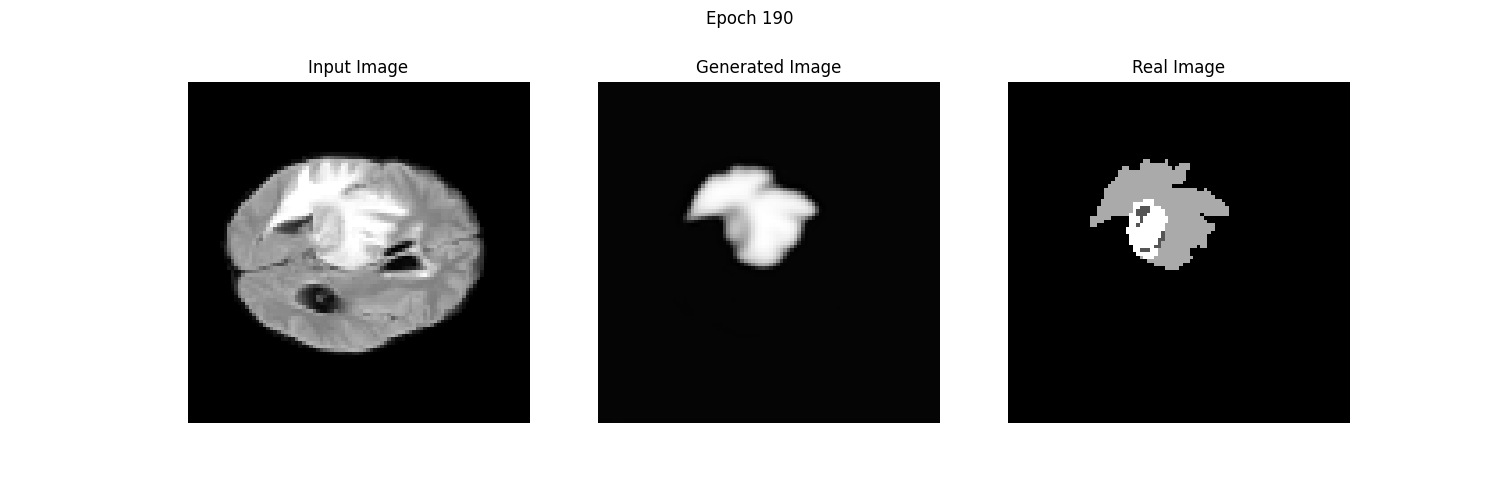
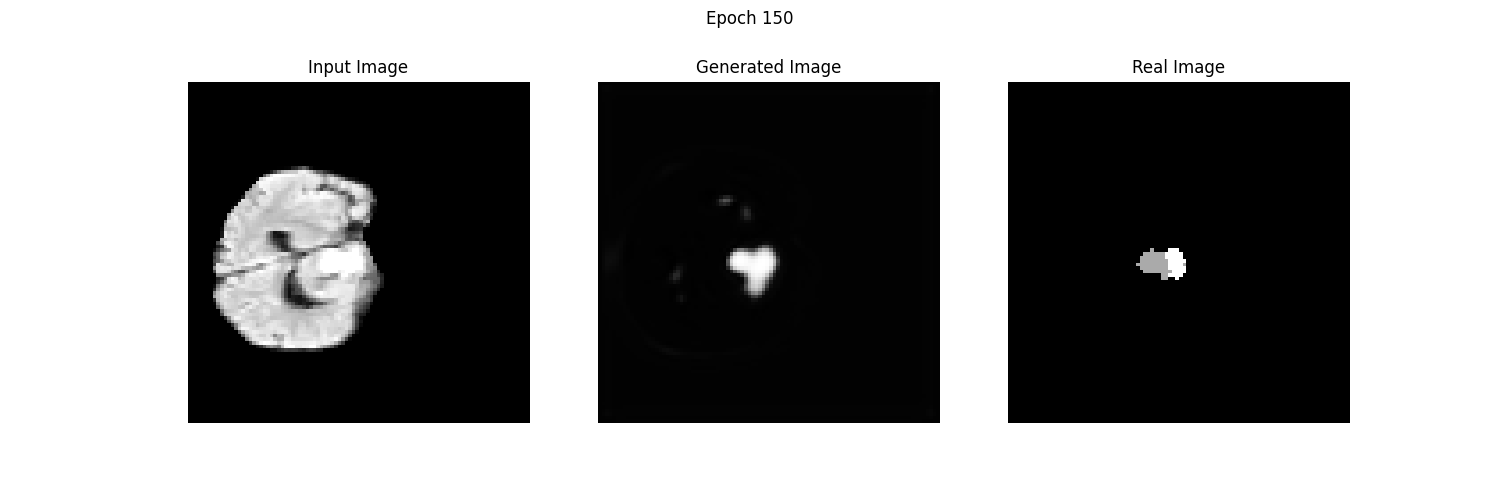
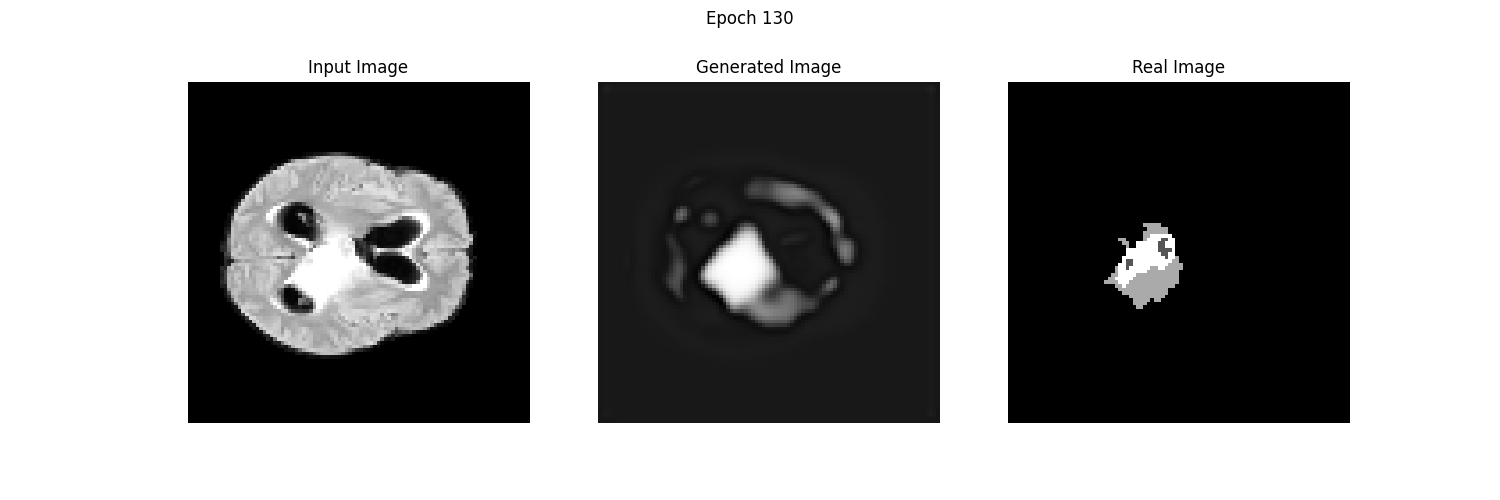
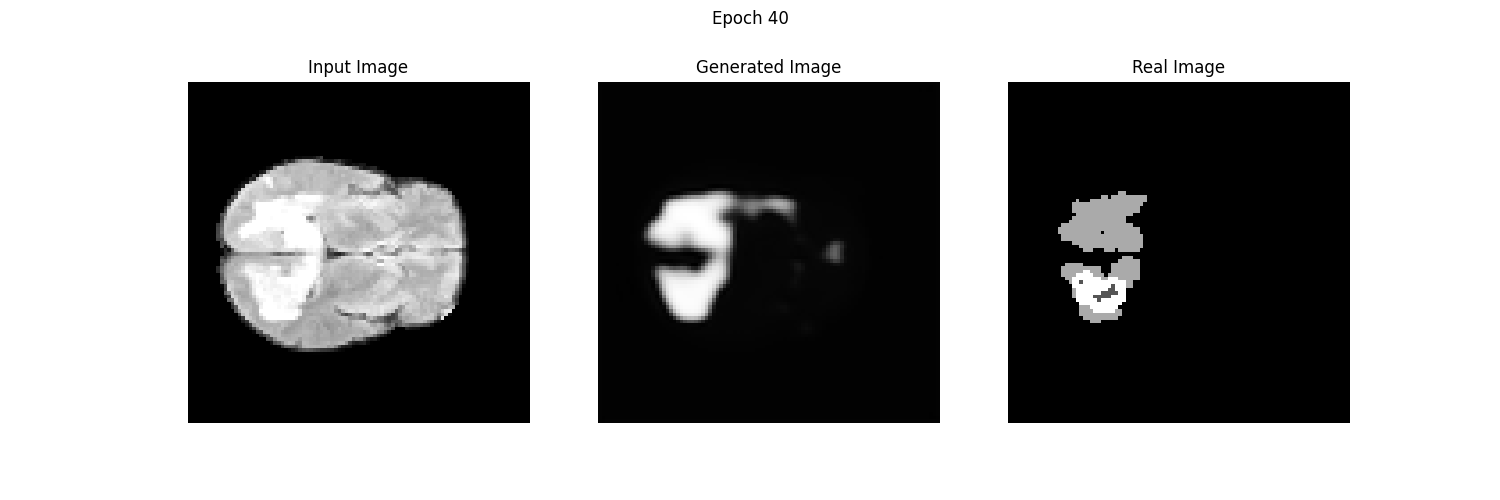
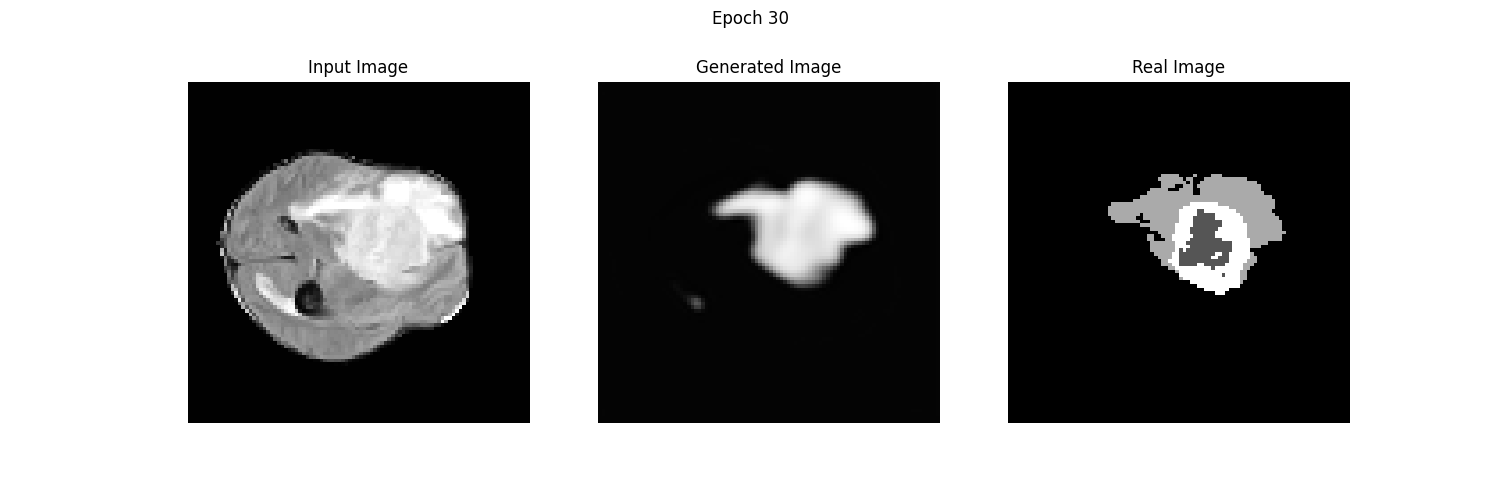

In [1]:
!pip -q install torchio
!pip -q install monai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.4/177.4 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.1 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.5 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 85.6 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pylibcugraph-cu12 24.12.0

### Imports Libraries

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split, Subset

import os
import wandb
import time
import numpy as np
from glob import glob
import matplotlib.pyplot as plt


import torchio as tio
from torchio.data import SubjectsLoader, SubjectsDataset
from monai.networks.nets import SwinUNETR
from monai.losses import DiceCELoss

2025-04-27 11:26:40.063151: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745753200.243948      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745753200.298753      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
# Using GPU P100
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.__version__, device

('2.5.1+cu124', device(type='cuda'))

## Data Preparation 

In [4]:
# --- Download Dataset --- #

!gdown -q 1wEwKrXkXORCooDrH_92FlrTJYZ-0b9CH # BraTS-SSA
!unzip -q ASNR-MICCAI-BraTS2023-SSA-Challenge-TrainingData_V2.zip

In [5]:
#--- WANDB LOGGING ---#

# Assignment: Create a WANDB account and generate your API Key
WANDB_API_KEY = "694068595800316e283e8baf783a5af5cbd510c9"  # ← Replace with your key
wandb.login(key=WANDB_API_KEY)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sirnero001 (sirnero001-university-of-nigeria-nsukka) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [6]:
# My Custom Dataset Class
class MyDataset(SubjectsDataset):
    def __init__(self, directory, transform=None):
        self.directory = directory
        self.transform = transform

        self.mri_paths = sorted(glob(os.path.join(directory, "**", "*t2f*nii.gz")))
        self.sm_paths = sorted(glob(os.path.join(directory, "**", "*seg*nii.gz")))

        self.subjects = [
            tio.Subject(mri=tio.ScalarImage(mri_path), seg_mask = tio.LabelMap(sm_path))
            for mri_path, sm_path in zip(self.mri_paths, self.sm_paths)
        ]
        super().__init__(self.subjects, transform=self.transform)

In [7]:
dataset = MyDataset(directory = '/kaggle/working/ASNR-MICCAI-BraTS2023-SSA-Challenge-TrainingData_V2')
dataloader = SubjectsLoader(dataset, batch_size=2, shuffle=True, num_workers=4)

In [8]:
batch = next(iter(dataloader))

torch.Size([2, 1, 240, 240, 155]) torch.Size([2, 1, 240, 240, 155])


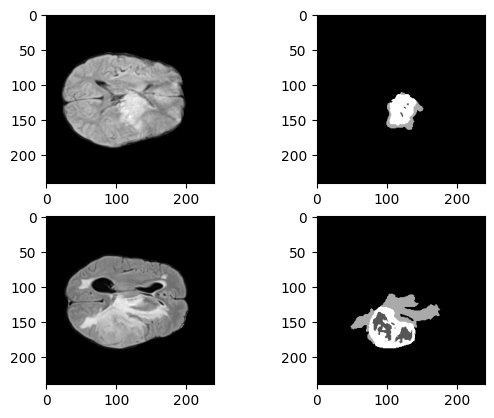

In [9]:
mri_data = batch['mri'][tio.DATA]
mask_data = batch['seg_mask'][tio.DATA]

print(mri_data.shape, mask_data.shape)
# Shape (B, C, H, W, D) Channel is always 0, Batch is dependent on the batch size 0 -> 1st img of the batch, 1 -> 2nd img

centre_slice = mri_data.shape[-1] // 2

#1st image in the batch
plt.subplot(2, 2, 1)
plt.imshow(mri_data[0, 0,:, :, centre_slice], cmap="gray")
plt.subplot(2, 2, 2)
plt.imshow(mask_data[0, 0,:, :, centre_slice], cmap="gray")

#2nd image in the batch
plt.subplot(2, 2, 3)
plt.imshow(mri_data[1, 0,:, :, centre_slice], cmap="gray")
plt.subplot(2, 2, 4)
plt.imshow(mask_data[1, 0,:, :, centre_slice], cmap="gray")

## Data Preprocessing

In [10]:
# My transformer
gen_transformer = tio.Compose(
    [
       tio.RescaleIntensity(out_min_max=(0, 1), percentiles=(0, 99.5)),
        tio.ZNormalization(),
        tio.Resample((2.4, 2.4, 2.2)), #Changes the voxel spacing. Smaller values give higher resolution
        tio.CropOrPad((128, 128, 64)), #Changes the voxel count and image size
        tio.ToCanonical(),       
    ]
)

train_augmentations = tio.Compose([
    tio.RandomFlip(axes=(0, 1, 2), p=0.7),
    tio.RandomAffine(scales=(0.9, 1.1), degrees=15, translation=5, p=0.6),
    tio.RandomElasticDeformation(num_control_points=7, max_displacement=7.5, p=0.3),
    tio.RandomBiasField(p=0.2),
    tio.RandomNoise(p=0.2),
])

train_transformer = tio.Compose([gen_transformer, train_augmentations])

## Creating training and test dataset

In [11]:
# Creating datasets and applying the appropriate transforms for train and test data
directory = "/kaggle/working/ASNR-MICCAI-BraTS2023-SSA-Challenge-TrainingData_V2"
full_train_dataset = MyDataset(directory=directory, transform=train_transformer)
full_test_dataset  = MyDataset(directory=directory, transform=gen_transformer)

In [12]:
train_size = int(0.8 * len(full_train_dataset))
test_size  = len(full_train_dataset) - train_size
train_idx, test_idx = random_split(range(len(full_train_dataset)), [train_size, test_size])

In [13]:
print("First 10 train indices:", train_idx.indices[:10])
print("First 10 test indices: ", test_idx.indices[:10])

First 10 train indices: [8, 40, 35, 45, 31, 26, 41, 10, 19, 2]
First 10 test indices:  [3, 34, 28, 15, 55, 57, 24, 9, 20, 44]


In [14]:
# Make simple Subsets
train_subset = Subset(full_train_dataset, train_idx)
test_subset  = Subset(full_test_dataset, test_idx)

train_loader = SubjectsLoader(train_subset, batch_size=1, shuffle=True,  num_workers=4)
test_loader  = SubjectsLoader(test_subset,  batch_size=1, shuffle=False, num_workers=4)

## The Model 

In [15]:
EPOCHS = 100
LR = 1e-4
WD = 1e-5
IMG_SIZE = (128,128,64)

In [16]:
wandb.init(
    project="Pix2Pix BraTS Segmentation",
    config={
        "epochs": EPOCHS,
        "batch_size": 1,
        "learning_rate": LR,
        "optimizer": "AdamW",
        "loss_function": "DiceCELoss",
        "architecture": "SwinUNETR",
        "img_size": IMG_SIZE,
        "patch_dropout": 0.1
    }
)

wandb_config = wandb.config

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


In [17]:
print(wandb_config)

{'epochs': 100, 'batch_size': 1, 'learning_rate': 0.0001, 'optimizer': 'AdamW', 'loss_function': 'DiceCELoss', 'architecture': 'SwinUNETR', 'img_size': [128, 128, 64], 'patch_dropout': 0.1}


In [18]:
swin_unet_model = SwinUNETR(
    img_size= wandb_config.img_size,
    in_channels=1,
    out_channels=1,
    feature_size=60,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    dropout_path_rate=wandb_config.patch_dropout,
    use_checkpoint=True,
    use_v2 = False
).to(device)

/usr/local/lib/python3.11/dist-packages/monai/utils/deprecate_utils.py:221: FutureWarning: monai.networks.nets.swin_unetr SwinUNETR.__init__:img_size: Argument `img_size` has been deprecated since version 1.3. It will be removed in version 1.5. The img_size argument is not required anymore and checks on the input size are run during forward().
  warn_deprecated(argname, msg, warning_category)


In [19]:
# Defining the hyperparams: loss function and the optimizer
loss_fxn =  DiceCELoss(to_onehot_y=False, sigmoid=True)
optimizer = optim.AdamW(swin_unet_model.parameters(), lr=wandb_config.learning_rate, weight_decay=WD)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=wandb_config.epochs)

## Model Training

In [20]:
start = time.time()

for epoch in range(wandb_config.epochs):
    swin_unet_model.train() #Set model to training mode
    running_loss = 0.0
    for batch in train_loader:
        mri_img = batch["mri"][tio.DATA].to(device)
        mask_img = batch['seg_mask'][tio.DATA].to(device)
        
        optimizer.zero_grad() #Clear prev gradients

        gen_img = swin_unet_model(mri_img) # Forward pass to create a simulated mask image

        loss = loss_fxn(gen_img, mask_img) # Calculate loss
        loss.backward() # Backpropagate the gradients
        optimizer.step() # Update model weights
        
        running_loss += loss.item()

    scheduler.step()

    avg_loss = running_loss / len(train_loader)

    # Log train loss per epoch
    wandb.log({
        "train_loss": avg_loss,
        "epoch": epoch,
        "learning_rate": scheduler.get_last_lr()[0]
    })

    print(f"Epoch {epoch+1}/{wandb_config.epochs} - Loss: {avg_loss:.4f}")


duration = time.time() - start
print(f"Total training time: {duration//60} mins")

Epoch 1/100 - Loss: 1.0359
Epoch 2/100 - Loss: 0.8369
Epoch 3/100 - Loss: 0.7244
Epoch 4/100 - Loss: 0.6935
Epoch 5/100 - Loss: 0.6183
Epoch 6/100 - Loss: 0.5493
Epoch 7/100 - Loss: 0.4795
Epoch 8/100 - Loss: 0.3745
Epoch 9/100 - Loss: 0.2655
Epoch 10/100 - Loss: 0.2022
Epoch 11/100 - Loss: 0.1696
Epoch 13/100 - Loss: 0.0449
Epoch 14/100 - Loss: 0.0057
Epoch 15/100 - Loss: -0.0708
Epoch 16/100 - Loss: -0.0834
Epoch 17/100 - Loss: -0.1604
Epoch 18/100 - Loss: -0.1758
Epoch 19/100 - Loss: -0.2047
Epoch 20/100 - Loss: -0.2980
Epoch 21/100 - Loss: -0.2959
Epoch 22/100 - Loss: -0.3081
Epoch 23/100 - Loss: -0.3156
Epoch 24/100 - Loss: -0.3919
Epoch 25/100 - Loss: -0.4203
Epoch 26/100 - Loss: -0.3912
Epoch 27/100 - Loss: -0.4201
Epoch 28/100 - Loss: -0.4786
Epoch 29/100 - Loss: -0.5028
Epoch 30/100 - Loss: -0.5768
Epoch 31/100 - Loss: -0.5878
Epoch 32/100 - Loss: -0.6266
Epoch 33/100 - Loss: -0.6657
Epoch 34/100 - Loss: -0.6626
Epoch 35/100 - Loss: -0.6946
Epoch 36/100 - Loss: -0.7700
Epoch 3

In [21]:
torch.save(swin_unet_model.state_dict(), 'swin_unet_model_v1.pth')
# Save model to wandb
wandb.save("swin_unet_model_v1.pth")

['/kaggle/working/wandb/run-20250427_112747-c93z5rrz/files/swin_unet_model_v1.pth']

In [22]:
swin_unet_model.eval()

# Counter for how many subjects we've plotted
pred_masks = []
true_masks = []

# Iterate through the test_loader
for batch in test_loader:
    input_mri = batch['mri'][tio.DATA].to(device)    # [B,1,H,W,D]
    true_mask = batch['seg_mask'][tio.DATA].to(device)   # [B,1,H,W,D]

    # Run inference
    with torch.no_grad(): # Temporarily disable gradient tracking to save resources
        logits = swin_unet_model(input_mri)  # Generate the raw logits 
        probs = torch.sigmoid(logits) # Turn logits to probabilities between 0 and 1
        pred_mask = (probs > 0.5).float()
        pred_masks.extend(pred_mask.cpu().numpy())
        true_masks.extend(true_mask.cpu().numpy())          

In [23]:
#Convert lists to numpy arrays and squeeze to remove the unnecessary singleton dimensions ie [B,1,H,W,D] -> [B,H,W,D]
pred_array = np.array(pred_masks).squeeze() 
true_array = np.array(true_masks).squeeze()

accuracy = np.mean(pred_array == true_array)
print(f"The model's accuracy is {accuracy:.4f}")

# Log metrics on Wandb
wandb.log({"Accuracy": accuracy})

wandb.finish()

The model's accuracy is 0.9884


Accuracy,▁
epoch,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇███
learning_rate,███████▇▇▇▇▇▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁
train_loss,█▇▆▆▆▅▅▅▅▄▄▄▄▄▃▃▃▃▃▂▂▃▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁
Accuracy,0.98836
epoch,99
learning_rate,0
train_loss,-1.3665


In [24]:
#Function to visualize image
def visualise_samples(model, testloader, num_of_pix=5):
    """
    Args:
        model : The trained model.
        testloader (torchio.data.loader.SubjectsLoader): DataLoader containing the test dataset.
        num_of_pix (int, optional): The number of test samples to visualize. Defaults to 5.

    Returns:
        None: Displays plots for the input MRI, true segmentation mask, and predicted mask.
    """
    model.eval()
   
    # Counter for how many subjects we've plotted
    num_shown = 0
    max_to_show = num_of_pix
    
    # Iterate through the test_loader
    for batch in testloader:
        input_mri = batch['mri'][tio.DATA].to(device)    # [B,1,H,W,D]
        true_mask = batch['seg_mask'][tio.DATA].to(device)   # [B,1,H,W,D]
    
        # Run inference
        with torch.no_grad(): # Temporarily disable gradient tracking to save resources
            logits = model(input_mri)  # Generate the raw logits 
            probs = torch.sigmoid(logits) # Turn logits to probabilities between 0 and 1
        
        B, C, H, W, D = input_mri.shape
        z = D // 2  # Get the middle axial slice
    
        # Loop over items in this batch
        for b in range(B):
            if num_shown >= max_to_show:
                break
    
            mri_slice  = input_mri [b, 0, :, :, z].cpu().numpy()
            true_slice = true_mask[b, 0, :, :, z].cpu().numpy()
            pred_slice = probs[b, 0, :, :, z].cpu().numpy()
    
            plt.figure(figsize=(12, 4))
    
            plt.subplot(1, 3, 1)
            plt.imshow(mri_slice, cmap='gray')
            plt.title(f"Sample {num_shown+1}\nOriginal MRI")
            plt.axis('off')
    
            plt.subplot(1, 3, 2)
            plt.imshow(true_slice, cmap='gray')
            plt.title(f"Sample {num_shown+1}\nTrue Image")
            plt.axis('off')
    
            plt.subplot(1, 3, 3)
            plt.imshow(pred_slice, cmap='gray')
            plt.title(f"Sample {num_shown+1}\nGenerated Image")
            plt.axis('off')
    
            plt.tight_layout()
            plt.show()
    
            num_shown += 1
    
        if num_shown >= max_to_show:
            break

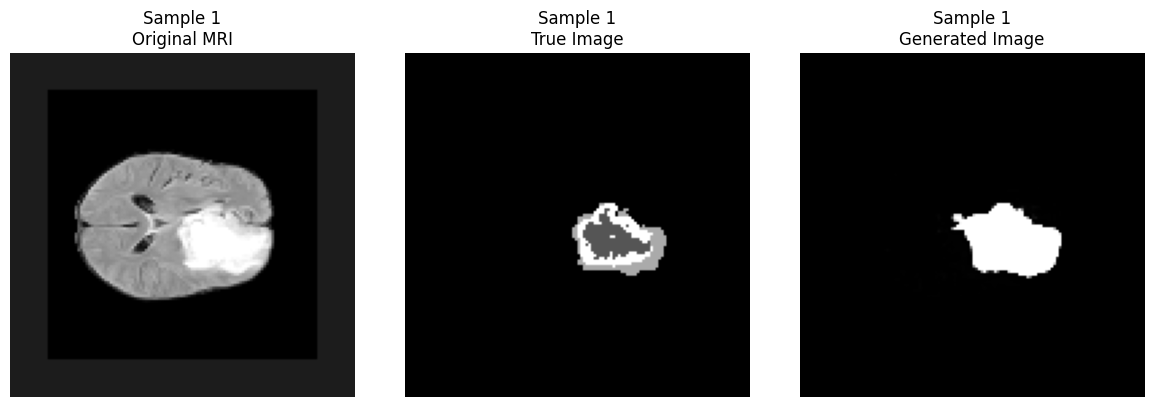

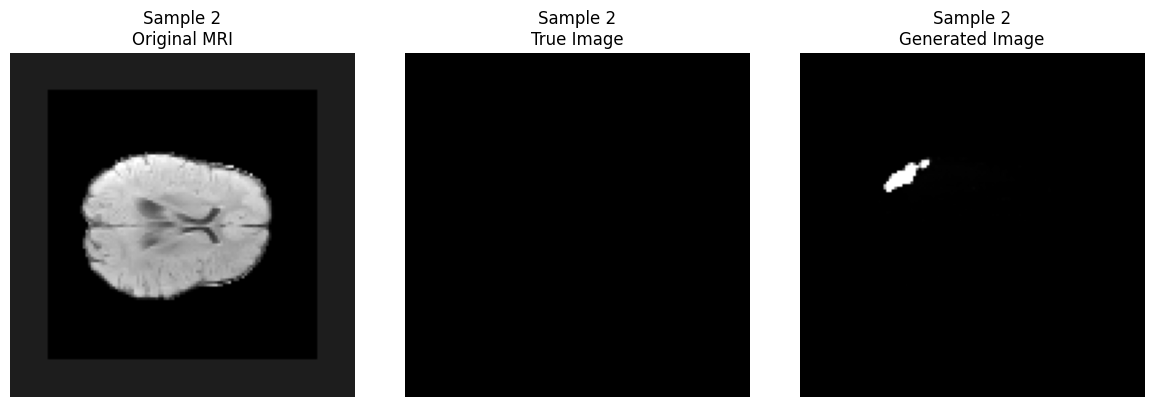

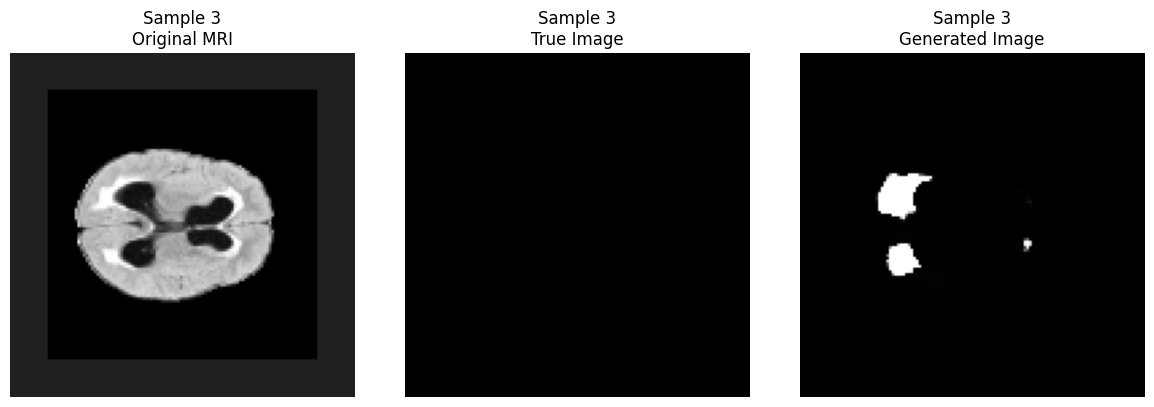

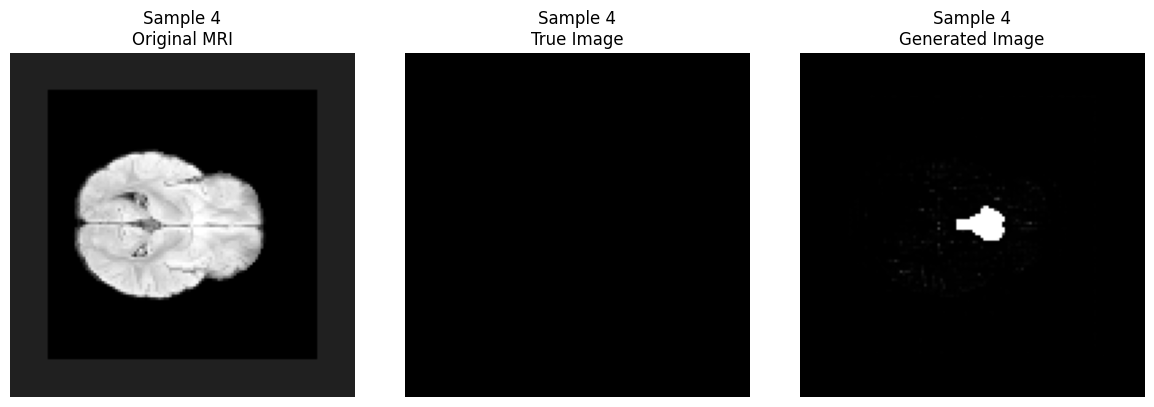

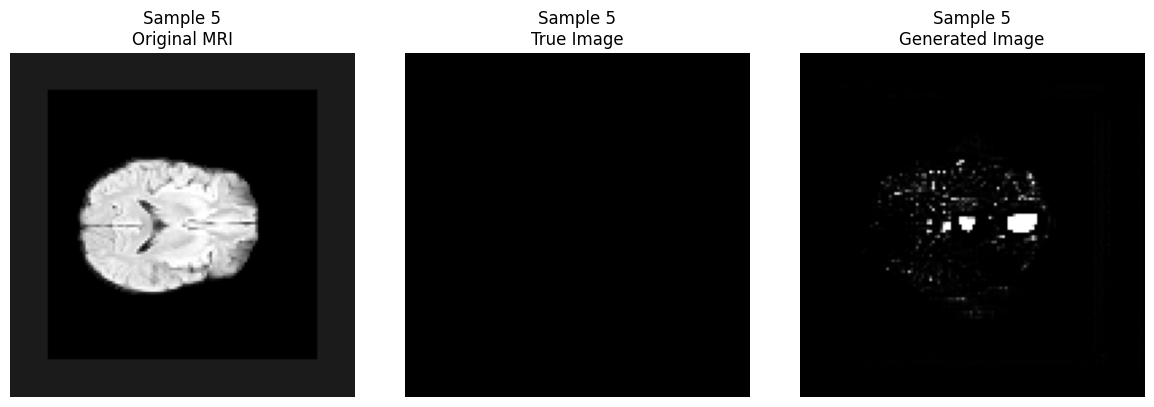

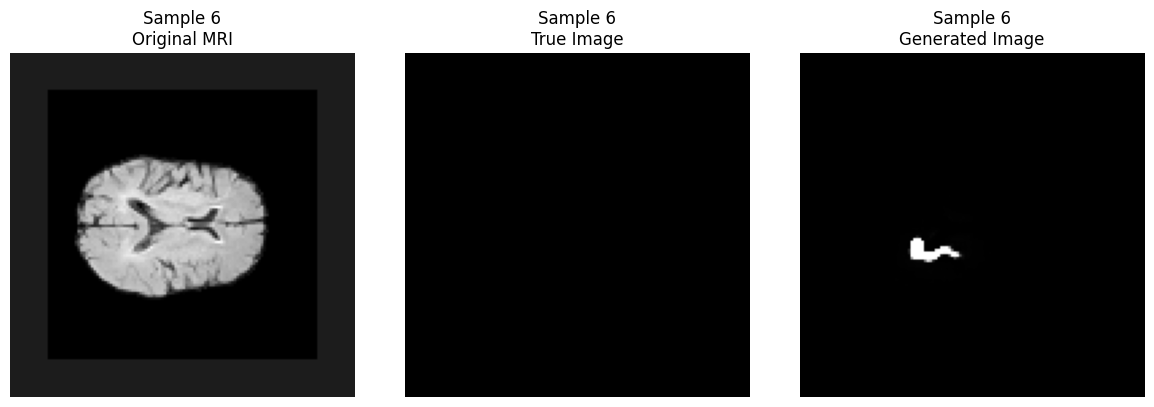

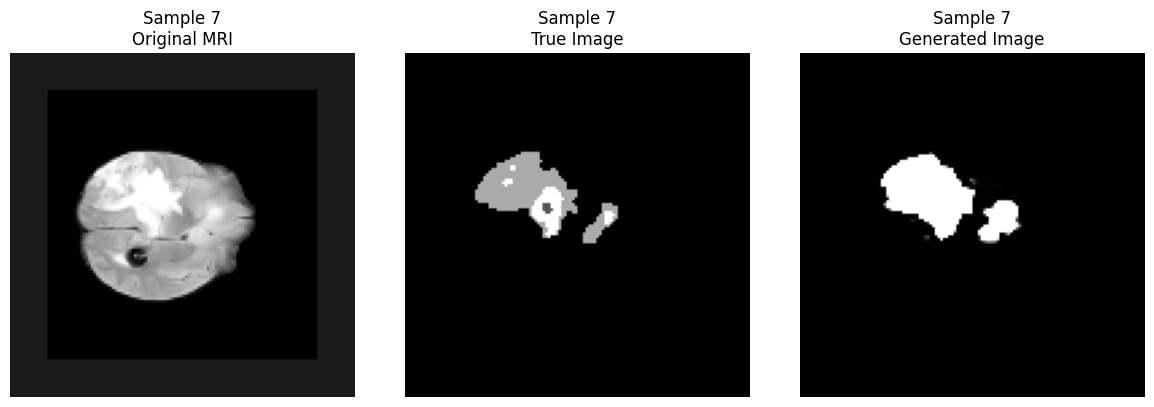

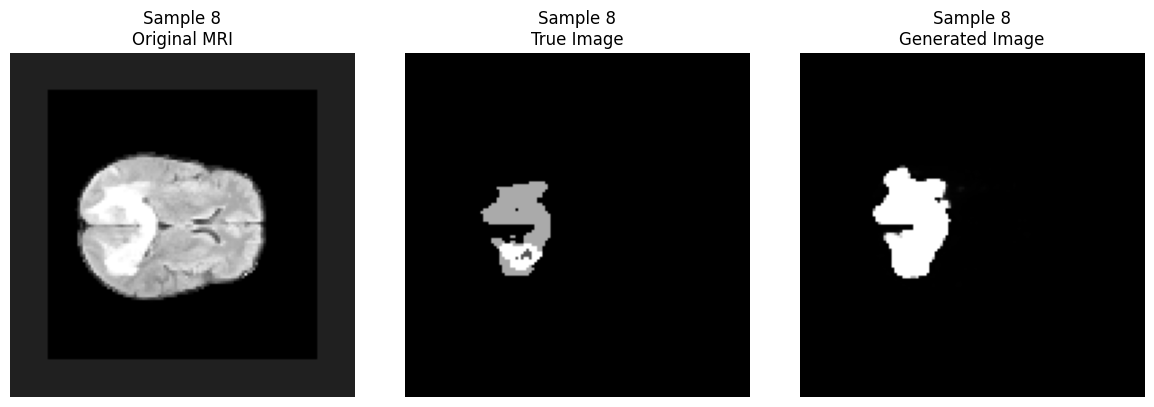

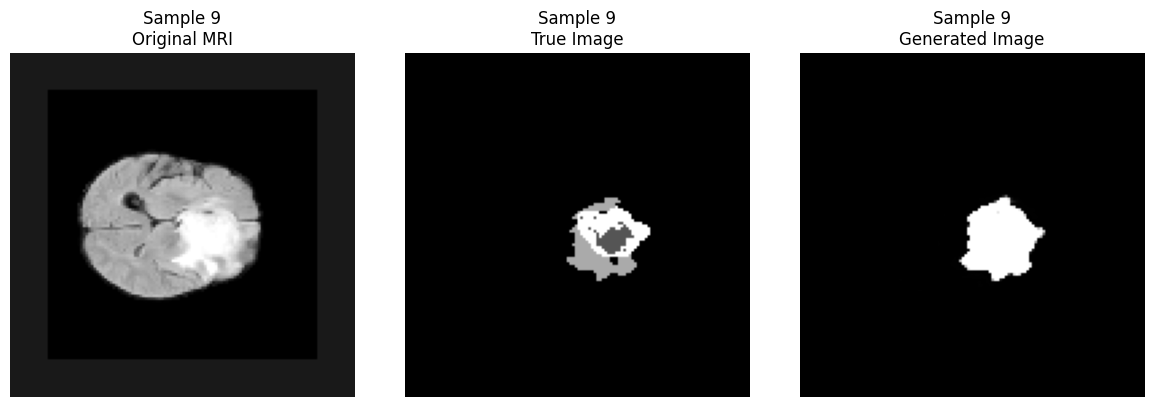

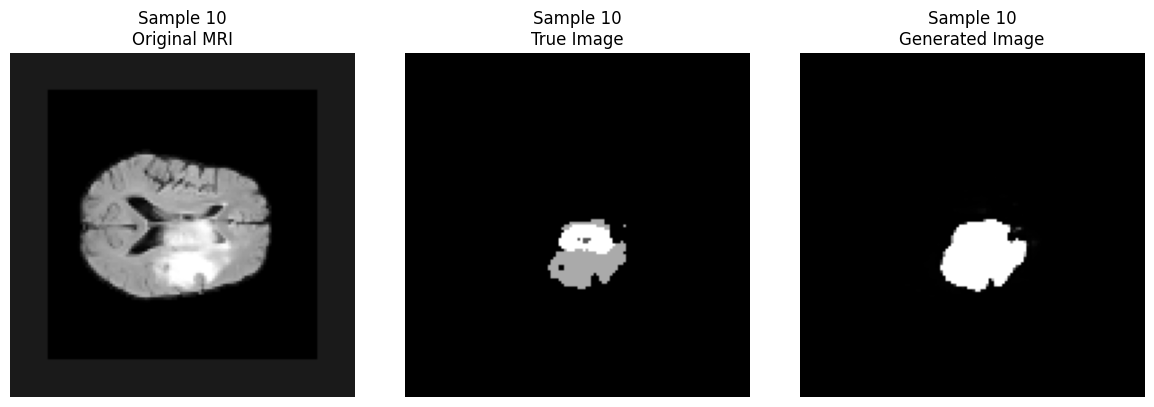

In [27]:
visualise_samples(model=swin_unet_model, testloader=test_loader, num_of_pix=10)

In [26]:
# # Loading saved model
# # Redefine the model architecture exactly as before
# swin_unet_generator = SwinUNETR(
#     img_size=(96, 96, 64),
#     in_channels=1,
#     out_channels=1,
#     feature_size=48,
#     drop_rate=0.0,
#     attn_drop_rate=0.0,
#     dropout_path_rate=0.1,
#     use_checkpoint=True,
#     use_v2=False
# ).to(device)

# # Load the saved weights
# swin_unet_generator.load_state_dict(torch.load('swin_unet_generator.pth'))
# swin_unet_generator.eval()  # Set it to evaluation mode
